In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

In [2]:
users = pd.read_csv("users.csv")
orders = pd.read_csv("orders.csv")
events = pd.read_csv("events.csv")
print(users.head(3))
print(users.describe())
print(users.info())
print(users.dtypes)

print(orders.head(3))
print(orders.describe())
print(orders.info())
print(orders.dtypes)

print(events.head(3))
print(events.describe())
print(events.info())
print(events.dtypes)

  user_id    reg_date channel city age_group
0   U0000  2026-08-03    社交裂变   武汉       45+
1   U0001  2026-09-22    社交裂变   成都     35-44
2   U0002  2026-09-14    社交裂变   西安       45+
       user_id    reg_date channel  city age_group
count     1200        1200    1200  1200      1167
unique    1200          55       3     5         4
top      U0000  2026-09-04    广告投放    成都     18-24
freq         1          34     700   260       308
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   user_id    1200 non-null   object
 1   reg_date   1200 non-null   object
 2   channel    1200 non-null   object
 3   city       1200 non-null   object
 4   age_group  1167 non-null   object
dtypes: object(5)
memory usage: 47.0+ KB
None
user_id      object
reg_date     object
channel      object
city         object
age_group    object
dtype: object
  order_id user_id  order_

In [3]:
# 重复值
print(users.duplicated().sum())
print(orders.duplicated().sum())
print(events.duplicated().sum())

0
0
0


In [4]:
# 缺失值
print(users.isnull().sum())
print(orders.isnull().sum())
print(events.isnull().sum())


user_id       0
reg_date      0
channel       0
city          0
age_group    33
dtype: int64
order_id          0
user_id           0
order_date        0
order_amount      0
pay_date        105
status            0
category          0
dtype: int64
event_id      0
user_id       0
event_date    0
event_type    0
category      0
device        0
dtype: int64


  user_id    reg_date channel city age_group  amount_sum  order_num  \
0   U0000  2026-08-03    社交裂变   武汉       45+         0.0        0.0   
1   U0001  2026-09-22    社交裂变   成都     35-44         0.0        0.0   
2   U0002  2026-09-14    社交裂变   西安       45+       166.0        1.0   

     last_pay   first_pay  event_total  view_num  addbuy_num  last_event  
0         NaN         NaN            2         2           0  2026-08-03  
1         NaN         NaN            1         1           0  2026-09-22  
2  2026-09-19  2026-09-19           10         6           2  2026-09-19  
channel
广告投放    700
社交裂变    200
自然流量    300
Name: user_id, dtype: int64
**************************************************
channel
广告投放    63.078571
社交裂变    84.140000
自然流量    89.796667
dtype: float64
**************************************************
channel
广告投放    0.311429
社交裂变    0.345000
自然流量    0.360000
Name: user_id, dtype: float64
===== 各渠道7日活跃留存率 =====
广告投放    0.530
社交裂变    0.635
自然流量    0.720
dtype: flo

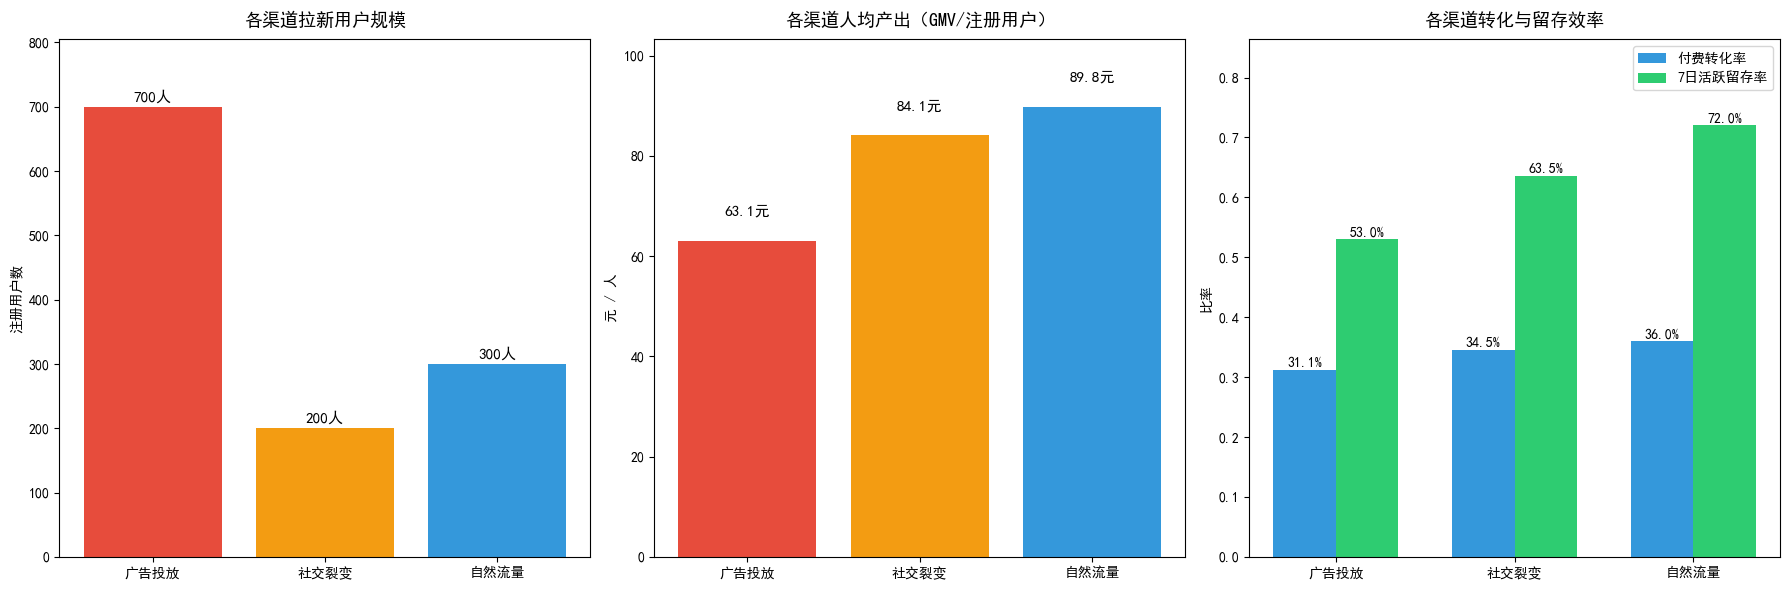

In [29]:
# q1
valid_orders = orders[(orders["status"] != "已退货") & (orders["pay_date"].notna())]
o_agg = valid_orders.groupby("user_id").agg(
    amount_sum = ("order_amount", "sum"),
    order_num = ("order_id", "nunique"),
    last_pay = ("pay_date", "max"),
    first_pay = ("pay_date", "min")
).reset_index()

# 事件表聚合
e_agg = events.groupby("user_id").agg(
    event_total = ("event_id", "count"),
    view_num = ("event_type", lambda x: (x == "浏览").sum()),
    addbuy_num = ("event_type", lambda x: (x == "加购").sum()),
    last_event = ("event_date", "max")
).reset_index()

# 三表合并
all_merge = pd.merge(users, o_agg, on="user_id", how="left")
all_merge = pd.merge(all_merge, e_agg, on="user_id", how="left")

fill_cols = ["amount_sum", "order_num", "event_total", "view_num", "addbuy_num"]
all_merge[fill_cols] = all_merge[fill_cols].fillna(0)
print(all_merge.head(3))
# 渠道指标计算
p_number = all_merge.groupby("channel")["user_id"].nunique()
print(p_number)
print("*" * 50)

# 
channel_stats = all_merge.groupby("channel").agg(
    amount_sum = ("amount_sum", "sum"),
    pay_p = ("user_id", "nunique")
)
avg_p_gmv = channel_stats["amount_sum"] / p_number
print(avg_p_gmv)
pay_p = all_merge[all_merge[ "order_num" ] > 0 ].groupby( "channel" )[ "user_id" ].nunique()
pay_rate = pay_p / p_number
print("*" * 50)
print(pay_rate)

# 7天留存计算
event_with_reg = pd.merge(
    events[["user_id", "event_date", "event_type"]],
    users[["user_id", "reg_date", "channel"]],
    on = "user_id",
    how = "left"
)

event_with_reg["event_date"] = pd.to_datetime(event_with_reg["event_date"])
event_with_reg["reg_date"] = pd.to_datetime(event_with_reg["reg_date"])
event_with_reg["day_index"] = (event_with_reg["event_date"] - event_with_reg["reg_date"]).dt.days
active_7d_users = event_with_reg[
    event_with_reg[ "day_index" ].between( 1 , 7 )
][ "user_id" ].unique()


active_7d_rate = pd.Series(dtype = float)

for channel in p_number.index:
    
    channel_reg = users[users["channel"] == channel]["user_id"].unique()
    
    active_count = len(set(channel_reg) & set(active_7d_users))
    
    active_7d_rate[channel] = active_count / len(channel_reg)

print("===== 各渠道7日活跃留存率 =====")
print(active_7d_rate.round(4))
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 6))
channel_colors = ["#e74c3c", "#f39c12", "#3498db"]  # 红/橙/蓝 对应三个渠道
channel_names = p_number.index  # 渠道名称，和你已有变量完全对齐

# ---- 左图：各渠道拉新用户规模 ----
bars1 = ax1.bar(
    channel_names,
    p_number.values,
    color=channel_colors
)
for bar in bars1:
    height = bar.get_height()
    ax1.text(
        bar.get_x() + bar.get_width()/2,
        height + 8,
        f"{int(height)}人",
        ha="center",
        fontsize=11
    )
ax1.set_title("各渠道拉新用户规模", fontsize=13, pad=10)
ax1.set_ylabel("注册用户数")
ax1.set_ylim(0, max(p_number.values) * 1.15)

# ---- 中图：各渠道人均GMV（钱花得值不值核心指标） ----
bars2 = ax2.bar(
    channel_names,
    avg_p_gmv.values,
    color=channel_colors
)
for bar in bars2:
    height = bar.get_height()
    ax2.text(
        bar.get_x() + bar.get_width()/2,
        height + 5,
        f"{height:.1f}元",
        ha="center",
        fontsize=11
    )
ax2.set_title("各渠道人均产出（GMV/注册用户）", fontsize=13, pad=10)
ax2.set_ylabel("元 / 人")
ax2.set_ylim(0, max(avg_p_gmv.values) * 1.15)

# ---- 右图：付费转化率 vs 7日活跃留存率（分组柱状图） ----
x = range(len(channel_names))
bar_width = 0.35

# 付费转化率柱
bars3 = ax3.bar(
    [i - bar_width/2 for i in x],
    pay_rate.values,
    bar_width,
    label="付费转化率",
    color="#3498db"
)
# 7日活跃留存率柱
bars4 = ax3.bar(
    [i + bar_width/2 for i in x],
    active_7d_rate.values,
    bar_width,
    label="7日活跃留存率",
    color="#2ecc71"
)

# 加百分比标签
for bar in bars3:
    height = bar.get_height()
    ax3.text(
        bar.get_x() + bar.get_width()/2,
        height + 0.005,
        f"{height:.1%}",
        ha="center",
        fontsize=10
    )
for bar in bars4:
    height = bar.get_height()
    ax3.text(
        bar.get_x() + bar.get_width()/2,
        height + 0.005,
        f"{height:.1%}",
        ha="center",
        fontsize=10
    )

ax3.set_xticks(x)
ax3.set_xticklabels(channel_names)
ax3.set_title("各渠道转化与留存效率", fontsize=13, pad=10)
ax3.legend()
ax3.set_ylabel("比率")
ax3.set_ylim(0, max(max(pay_rate.values), max(active_7d_rate.values)) * 1.2)

plt.tight_layout()
plt.show()

457
247
73
0.38083333333333336
0.33243606998654107
0.14717741935483872
0.08235294117647059


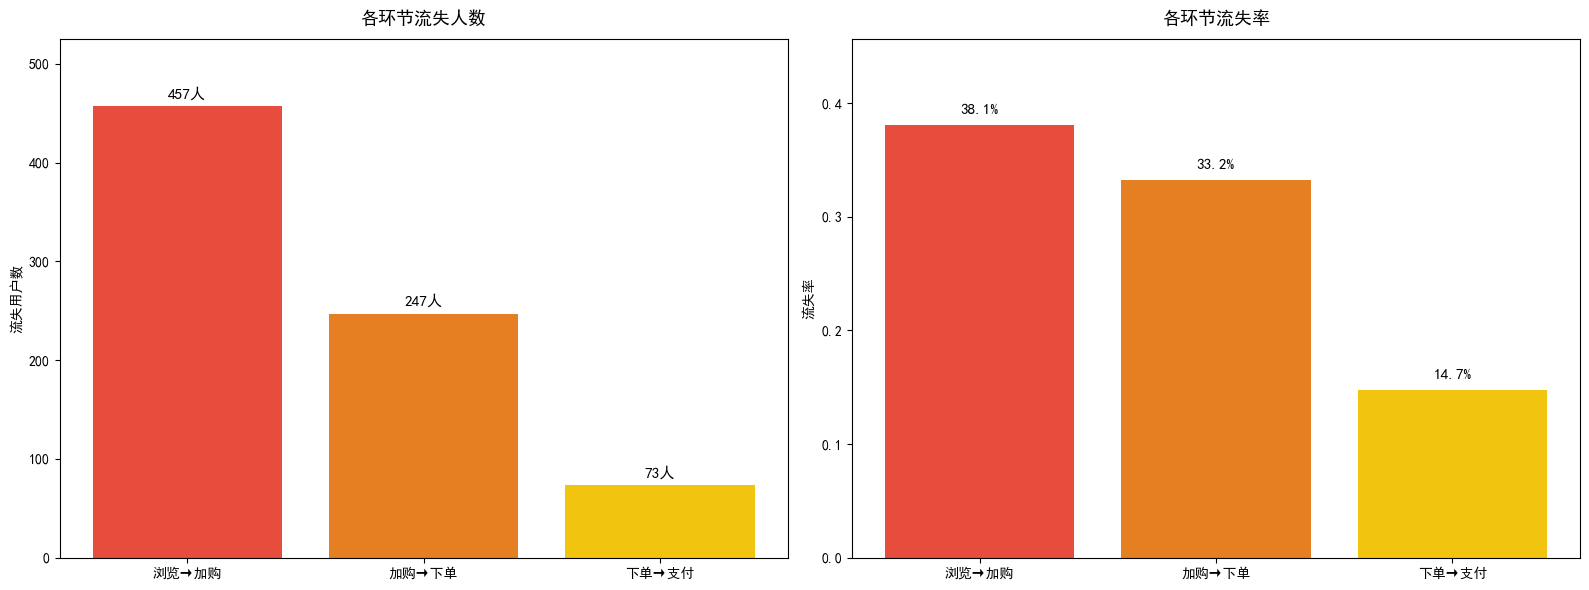

In [30]:
# q2
view_users = events[events["event_type"]=="浏览"]["user_id"].unique()
add_buy_users = events[events["event_type"]=="加购"]["user_id"].unique()
p_order_users = events[events["event_type"]=="下单"]["user_id"].unique()
pay_users = events[events["event_type"]=="支付"]["user_id"].unique()
return_users = events[events["event_type"]=="退货"]["user_id"].unique()

view = len(view_users)
add_buy = len(add_buy_users)
p_order = len(p_order_users)
pay = len(pay_users)

return_goods = len(return_users)

view_add = events[
    (events["event_type"] == "加购") & 
    events["user_id"].isin(view_users)
]["user_id"].nunique()
add_order = events[
    (events["event_type"] == "下单") & 
    events["user_id"].isin(add_buy_users)
]["user_id"].nunique()
order_pay = events[
    (events["event_type"] == "支付") & 
    events["user_id"].isin(p_order_users)
]["user_id"].nunique()

#
view_off = view-add_buy
add_off = add_buy-p_order
order_off = p_order-pay
print(view_off)
print(add_off)
print(order_off)
#
view_off_rate = view_off/view
add_off_rate = add_off/add_buy
order_off_rate = order_off/p_order
return_off_rate = len(events[events["event_type"]=="退货"])/len(events[events["event_type"]=="支付"])
print(view_off_rate)
print(add_off_rate)
print(order_off_rate)
print(return_off_rate)
#
stages = ["浏览→加购", "加购→下单", "下单→支付"]  # 三个流失环节
off_counts = [view_off, add_off, order_off]          # 各环节流失人数
off_rates = [view_off_rate, add_off_rate, order_off_rate] # 各环节流失率
colors = ["#e74c3c", "#e67e22", "#f1c40f"]           # 红→橙→黄，流失严重度递减

# ========== 创建画布：1行2列，同时看流失人数 + 流失率 ==========
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# ---- 左图：各环节流失人数 ----
bars1 = ax1.bar(stages, off_counts, color=colors)
# 柱子上标注具体人数
for bar in bars1:
    height = bar.get_height()
    ax1.text(
        bar.get_x() + bar.get_width()/2,
        height + 8,
        f"{int(height)}人",
        ha="center",
        fontsize=11
    )
ax1.set_title("各环节流失人数", fontsize=13, pad=10)
ax1.set_ylabel("流失用户数")
ax1.set_ylim(0, max(off_counts) * 1.15)

# ---- 右图：各环节流失率 ----
bars2 = ax2.bar(stages, off_rates, color=colors)
# 柱子上标注百分比
for bar in bars2:
    height = bar.get_height()
    ax2.text(
        bar.get_x() + bar.get_width()/2,
        height + 0.01,
        f"{height:.1%}",
        ha="center",
        fontsize=11
    )
ax2.set_title("各环节流失率", fontsize=13, pad=10)
ax2.set_ylabel("流失率")
ax2.set_ylim(0, max(off_rates) * 1.2)

# 全局布局调整
plt.tight_layout()
plt.show()

  age_group  t_amount  avg_amount  t_orders
0     18-24   20896.0   67.844156     117.0
1     25-34   24042.0   80.949495     116.0
2     35-44   19462.0   68.048951     107.0
  city  t_amount  avg_amount  t_orders
0   成都   23145.0   89.019231     121.0
1   武汉   15201.0   66.379913      80.0
2   西安   16259.0   72.262222      86.0


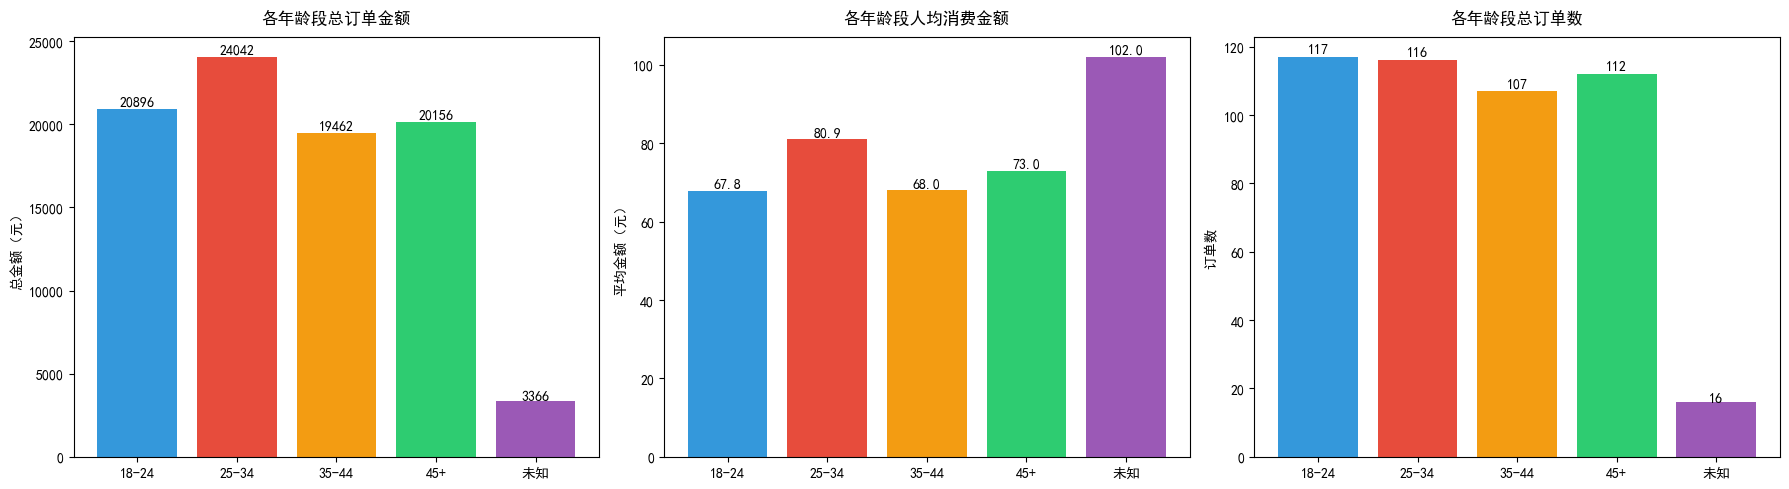

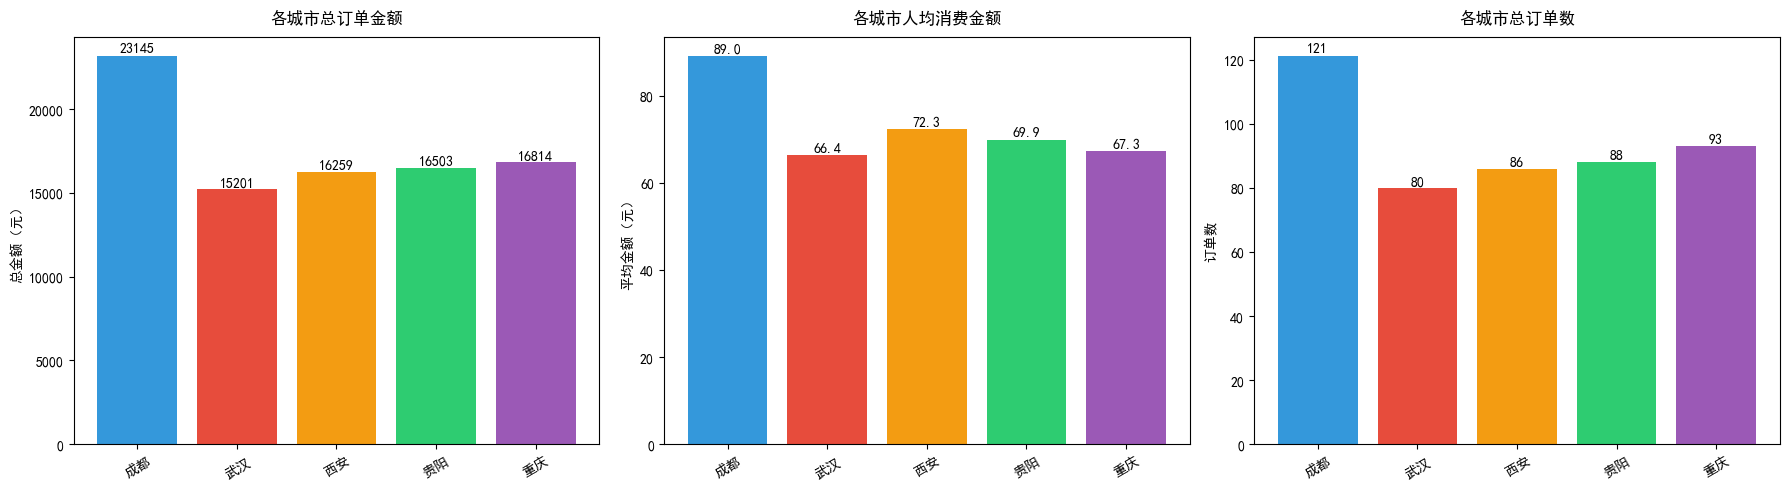

In [31]:
# q3
all_merge["age_group"] = all_merge["age_group"].fillna("未知")
age_stats = all_merge.groupby("age_group").agg(
    t_amount = ("amount_sum", "sum"),       
    avg_amount = ("amount_sum", "mean"),    
    t_orders = ("order_num", "sum")
).reset_index()

# 各城市统计
city_stats = all_merge.groupby("city").agg(
    t_amount = ("amount_sum", "sum"),
    avg_amount = ("amount_sum", "mean"),
    t_orders = ("order_num", "sum")
).reset_index()
print(age_stats.head(3))
print(city_stats.head(3))
#
fig1, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 5))
age_colors = ["#3498db", "#e74c3c", "#f39c12", "#2ecc71", "#9b59b6"]  # 按年龄段数量自动取色

# 左图：总订单金额
bars1 = ax1.bar(age_stats["age_group"], age_stats["t_amount"], color=age_colors[:len(age_stats)])
for bar in bars1:
    height = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2, height * 1.01, f"{int(height)}", ha="center", fontsize=10)
ax1.set_title("各年龄段总订单金额", fontsize=12, pad=10)
ax1.set_ylabel("总金额（元）")

# 中图：平均订单金额
bars2 = ax2.bar(age_stats["age_group"], age_stats["avg_amount"], color=age_colors[:len(age_stats)])
for bar in bars2:
    height = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2, height * 1.01, f"{height:.1f}", ha="center", fontsize=10)
ax2.set_title("各年龄段人均消费金额", fontsize=12, pad=10)
ax2.set_ylabel("平均金额（元）")

# 右图：总订单数
bars3 = ax3.bar(age_stats["age_group"], age_stats["t_orders"], color=age_colors[:len(age_stats)])
for bar in bars3:
    height = bar.get_height()
    ax3.text(bar.get_x() + bar.get_width()/2, height * 1.01, f"{int(height)}", ha="center", fontsize=10)
ax3.set_title("各年龄段总订单数", fontsize=12, pad=10)
ax3.set_ylabel("订单数")

plt.tight_layout()
plt.show()

# ========== 图2：各城市订单指标对比 ==========
fig2, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 5))
city_colors = ["#3498db", "#e74c3c", "#f39c12", "#2ecc71", "#9b59b6", "#95a5a6"]

# 左图：总订单金额
bars1 = ax1.bar(city_stats["city"], city_stats["t_amount"], color=city_colors[:len(city_stats)])
for bar in bars1:
    height = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2, height * 1.01, f"{int(height)}", ha="center", fontsize=10)
ax1.set_title("各城市总订单金额", fontsize=12, pad=10)
ax1.set_ylabel("总金额（元）")
ax1.tick_params(axis='x', rotation=30)  # 城市名过长时自动旋转，避免重叠

# 中图：平均订单金额
bars2 = ax2.bar(city_stats["city"], city_stats["avg_amount"], color=city_colors[:len(city_stats)])
for bar in bars2:
    height = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2, height * 1.01, f"{height:.1f}", ha="center", fontsize=10)
ax2.set_title("各城市人均消费金额", fontsize=12, pad=10)
ax2.set_ylabel("平均金额（元）")
ax2.tick_params(axis='x', rotation=30)

# 右图：总订单数
bars3 = ax3.bar(city_stats["city"], city_stats["t_orders"], color=city_colors[:len(city_stats)])
for bar in bars3:
    height = bar.get_height()
    ax3.text(bar.get_x() + bar.get_width()/2, height * 1.01, f"{int(height)}", ha="center", fontsize=10)
ax3.set_title("各城市总订单数", fontsize=12, pad=10)
ax3.set_ylabel("订单数")
ax3.tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

  category  view_pv  view_uv  view_user_count
0       家居      747      573              747
1       数码      741      565              741
2       服饰      780      576              780
3       美妆      763      585              763
4       食品      737      559              737
468
  category  amount_sum  order_count  avg_amount  pay_user
0       家居       17065           92  185.489130        91
1       数码       17439           96  181.656250        93
2       服饰       17020           91  187.032967        87
3       美妆       17431           97  179.701031        94
4       食品       18967           92  206.163043        87
  category  view_pv  view_uv  view_user_count  amount_sum  order_count  \
0       家居      747      573              747       17065           92   
1       数码      741      565              741       17439           96   
2       服饰      780      576              780       17020           91   
3       美妆      763      585              763       17431           97   
4 

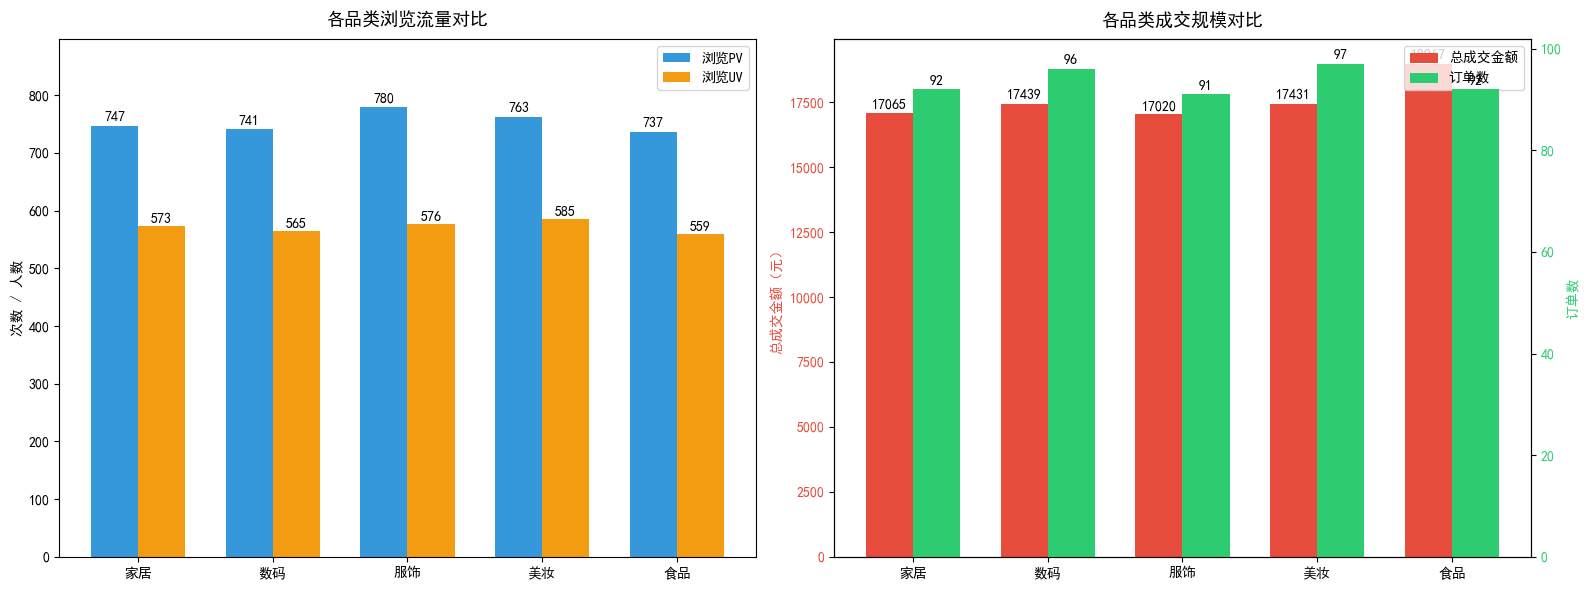

In [32]:
# q4
category_view = events[
    events["event_type"] == "浏览"
].groupby("category").agg(
    view_pv = ("event_id", "count"),       # 浏览量PV：浏览事件总次数
    view_uv = ("user_id", "nunique"),      # 浏览量UV：浏览去重用户数
    view_user_count = ("user_id", "count") # 同PV，用于校验
).reset_index()

print(category_view)
effect_orders = orders[(orders["pay_date"].notna()) &(orders["status"]!="已退货")]
print(len(effect_orders))
category_order = effect_orders.groupby("category").agg(
    amount_sum = ("order_amount", "sum"),
    order_count = ("order_id", "nunique"),
    avg_amount = ("order_amount", "mean"),
    pay_user = ("user_id", "nunique")
).reset_index()
print(category_order)
order_event = pd.merge(category_view,category_order ,on="category",how="outer")
print(order_event)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
category_colors = ["#3498db", "#e74c3c", "#f39c12", "#2ecc71", "#9b59b6"]
categories = order_event["category"]
x = range(len(categories))
bar_width = 0.35

# ---- 左图：各品类浏览PV / UV分组对比 ----
bars_pv = ax1.bar(
    [i - bar_width/2 for i in x], 
    order_event["view_pv"], 
    bar_width, 
    label="浏览PV", 
    color=category_colors[0]
)
bars_uv = ax1.bar(
    [i + bar_width/2 for i in x], 
    order_event["view_uv"], 
    bar_width, 
    label="浏览UV", 
    color=category_colors[2]
)

# 柱子标注数值
for bar in bars_pv:
    height = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2, height * 1.01, f"{int(height)}", ha="center", fontsize=10)
for bar in bars_uv:
    height = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2, height * 1.01, f"{int(height)}", ha="center", fontsize=10)

ax1.set_title("各品类浏览流量对比", fontsize=13, pad=10)
ax1.set_xticks(x)
ax1.set_xticklabels(categories)
ax1.set_ylabel("次数 / 人数")
ax1.legend()
ax1.set_ylim(0, order_event["view_pv"].max() * 1.15)

# ---- 右图：各品类成交金额 + 订单数（双轴柱状图） ----
# 左轴：总成交金额
bars_amount = ax2.bar(
    [i - bar_width/2 for i in x], 
    order_event["amount_sum"], 
    bar_width, 
    label="总成交金额", 
    color=category_colors[1]
)
ax2.set_ylabel("总成交金额（元）", color=category_colors[1])
ax2.tick_params(axis='y', labelcolor=category_colors[1])

# 右轴：订单数量
ax3 = ax2.twinx()
bars_order = ax3.bar(
    [i + bar_width/2 for i in x], 
    order_event["order_count"], 
    bar_width, 
    label="订单数", 
    color=category_colors[3]
)
ax3.set_ylabel("订单数", color=category_colors[3])
ax3.tick_params(axis='y', labelcolor=category_colors[3])

# 柱子标注数值
for bar in bars_amount:
    height = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2, height * 1.01, f"{int(height)}", ha="center", fontsize=10)
for bar in bars_order:
    height = bar.get_height()
    ax3.text(bar.get_x() + bar.get_width()/2, height * 1.01, f"{int(height)}", ha="center", fontsize=10)

ax2.set_title("各品类成交规模对比", fontsize=13, pad=10)
ax2.set_xticks(x)
ax2.set_xticklabels(categories)

# 合并双轴图例
lines1, labels1 = ax2.get_legend_handles_labels()
lines2, labels2 = ax3.get_legend_handles_labels()
ax2.legend(lines1 + lines2, labels1 + labels2, loc="upper right")

plt.tight_layout()
plt.show()

C:\Users\coo07\AppData\Local\Temp\ipykernel_20920\736647884.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  effect_orders["pay_date"] = pd.to_datetime(effect_orders["pay_date"])


    user_id last_pay_date  pay_times  total_amount
166   U0517    2026-08-18          3          1197
285   U0867    2026-09-22          2           994
86    U0264    2026-09-25          3           888
    user_id last_pay_date  pay_times  total_amount  recency_days
166   U0517    2026-08-18          3          1197            39
285   U0867    2026-09-22          2           994             4
86    U0264    2026-09-25          3           888             1


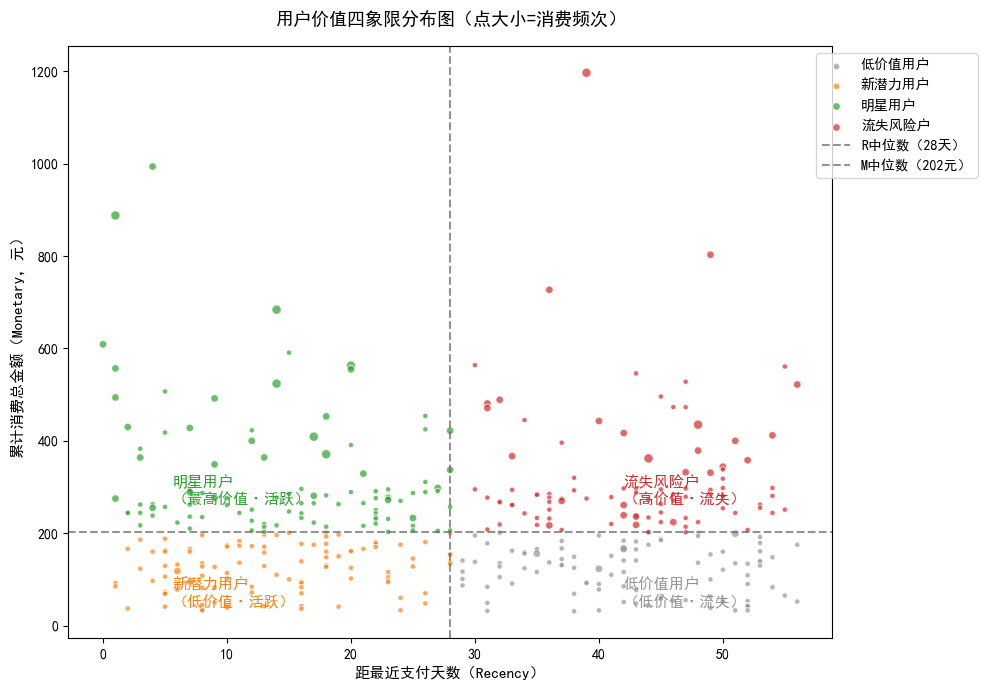

===== 各等级用户规模 =====
明星用户（最高等级）：101 人，占付费用户总数 25.6%
流失风险户：97 人，占付费用户总数 24.6%
新潜力用户：100 人，占付费用户总数 25.3%
低价值用户：97 人，占付费用户总数 24.6%

===== 最高等级：明星用户 完整名单 =====
    user_id last_pay_date  pay_times  total_amount  recency_days
0     U0867    2026-09-22          2           994             4
1     U0264    2026-09-25          3           888             1
2     U0059    2026-09-12          3           684            14
3     U0652    2026-09-26          2           609             0
4     U0061    2026-09-11          1           591            15
..      ...           ...        ...           ...           ...
96    U0498    2026-08-29          1           206            28
97    U0735    2026-09-14          1           206            12
98    U1106    2026-08-30          1           205            27
99    U0825    2026-09-13          1           203            13
100   U0357    2026-09-03          1           203            23

[101 rows x 5 columns]


In [33]:
# q5
effect_orders["pay_date"] = pd.to_datetime(effect_orders["pay_date"])
per_stats = effect_orders.groupby("user_id").agg(
    last_pay_date = ("pay_date", "max"),
    pay_times = ("order_id", "nunique"),
    total_amount = ("order_amount", "sum")
).reset_index()

per_stats = per_stats.sort_values("total_amount", ascending=False)
print(per_stats.head(3))
stats_date = per_stats["last_pay_date"].max()
per_stats["recency_days"] = (stats_date - per_stats["last_pay_date"]).dt.days
print(per_stats.head(3))

r_median = per_stats["recency_days"].median()
m_median = per_stats["total_amount"].median()

# ========== 2. 四象限划分规则（最高等级：明星用户） ==========
def get_quadrant(row):
    # 明星用户：近期活跃 + 高价值 → 最高等级，核心维护
    if row["recency_days"] <= r_median and row["total_amount"] >= m_median:
        return "明星用户"
    # 流失风险户：久未消费 + 高价值 → 次高价值，重点召回
    elif row["recency_days"] > r_median and row["total_amount"] >= m_median:
        return "流失风险户"
    # 新潜力用户：近期活跃 + 低价值 → 成长型，提升客单
    elif row["recency_days"] <= r_median and row["total_amount"] < m_median:
        return "新潜力用户"
    # 低价值用户：久未消费 + 低价值 → 最低等级，减少投入
    else:
        return "低价值用户"

# 给原表新增象限标签列，不修改原有字段
per_stats["quadrant"] = per_stats.apply(get_quadrant, axis=1)

# ========== 3. 绘制四象限散点图 ==========
fig, ax = plt.subplots(figsize=(10, 7))

# 象限对应配色
quad_colors = {
    "明星用户": "#2ca02c",
    "流失风险户": "#d62728",
    "新潜力用户": "#ff7f0e",
    "低价值用户": "#949494"
}

# 按象限分组绘制，点大小 = 支付次数（F维度）
for quad_name, group in per_stats.groupby("quadrant"):
    ax.scatter(
        x = group["recency_days"],
        y = group["total_amount"],
        s = group["pay_times"] * 15,
        color = quad_colors[quad_name],
        alpha = 0.7,
        edgecolors = "white",
        linewidth = 0.8,
        label = quad_name
    )

# 中位数切分线
ax.axvline(x = r_median, color = "#666666", linestyle = "--", alpha = 0.7, label = f"R中位数（{r_median:.0f}天）")
ax.axhline(y = m_median, color = "#666666", linestyle = "--", alpha = 0.7, label = f"M中位数（{m_median:.0f}元）")

# 象限标注
ax.text(r_median * 0.2, m_median * 1.3, "明星用户\n（最高价值·活跃）", fontsize=11, color="#2ca02c", fontweight="bold")
ax.text(r_median * 1.5, m_median * 1.3, "流失风险户\n（高价值·流失）", fontsize=11, color="#d62728", fontweight="bold")
ax.text(r_median * 0.2, m_median * 0.2, "新潜力用户\n（低价值·活跃）", fontsize=11, color="#ff7f0e", fontweight="bold")
ax.text(r_median * 1.5, m_median * 0.2, "低价值用户\n（低价值·流失）", fontsize=11, color="#949494", fontweight="bold")

ax.set_xlabel("距最近支付天数（Recency）", fontsize=11)
ax.set_ylabel("累计消费总金额（Monetary，元）", fontsize=11)
ax.set_title("用户价值四象限分布图（点大小=消费频次）", fontsize=13, pad=15)
ax.legend(loc="upper right", bbox_to_anchor=(1.2, 1))
plt.tight_layout()
plt.show()

# ========== 4. 拆分各等级用户 + 打印输出 ==========
# 各等级用户列表（按优先级排序）
star_users = per_stats[per_stats["quadrant"] == "明星用户"].sort_values("total_amount", ascending=False).reset_index(drop=True)
lost_risk_users = per_stats[per_stats["quadrant"] == "流失风险户"].sort_values("total_amount", ascending=False).reset_index(drop=True)
potential_users = per_stats[per_stats["quadrant"] == "新潜力用户"].sort_values("recency_days").reset_index(drop=True)
low_value_users = per_stats[per_stats["quadrant"] == "低价值用户"].sort_values("recency_days", ascending=False).reset_index(drop=True)

# 打印各等级规模概览
print("=" * 50)
print("===== 各等级用户规模 =====")
print(f"明星用户（最高等级）：{len(star_users)} 人，占付费用户总数 {len(star_users)/len(per_stats):.1%}")
print(f"流失风险户：{len(lost_risk_users)} 人，占付费用户总数 {len(lost_risk_users)/len(per_stats):.1%}")
print(f"新潜力用户：{len(potential_users)} 人，占付费用户总数 {len(potential_users)/len(per_stats):.1%}")
print(f"低价值用户：{len(low_value_users)} 人，占付费用户总数 {len(low_value_users)/len(per_stats):.1%}")
print("=" * 50)

# 重点输出：最高等级明星用户完整名单（按消费金额从高到低）
print("\n===== 最高等级：明星用户 完整名单 =====")
print(star_users[["user_id", "last_pay_date", "pay_times", "total_amount", "recency_days"]])